### Question 1: ROC AUC feature importance

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import roc_auc_score
from sklearn.model_selection import train_test_split

DATA_URL = "https://raw.githubusercontent.com/DataTalksClub/machine-learning-zoomcamp/main/cohorts/2026/data/course_lead_scoring_2026.csv"
df = pd.read_csv(DATA_URL)

print(f"Dataset shape: {df.shape}")
missing_values = df.isna().sum()
print("Missing values by feature before filling:")
print(missing_values[missing_values > 0])

for column in df.columns:
    if column == "converted":
        continue
    if pd.api.types.is_numeric_dtype(df[column]):
        df[column] = df[column].fillna(0.0)
    else:
        df[column] = df[column].fillna("NA")

df_full_train, df_test = train_test_split(df, test_size=0.2, random_state=1)
df_train, df_val = train_test_split(
    df_full_train, test_size=0.25, random_state=1
)

numerical_features = [
    "lead_score",
    "number_of_courses_viewed",
    "interaction_count",
    "annual_income",
]
y_train = df_train["converted"].to_numpy()
auc_by_feature = {}
for feature in numerical_features:
    feature_score = df_train[feature].to_numpy()
    auc = roc_auc_score(y_train, feature_score)
    if auc < 0.5:
        auc = roc_auc_score(y_train, -feature_score)
    auc_by_feature[feature] = auc

print("\nQ1 - ROC AUC by numerical feature (direction adjusted):")
for feature, auc in sorted(auc_by_feature.items(), key=lambda item: item[1], reverse=True):
    print(f"{feature}: {auc:.3f}")
print(f"Highest-AUC feature: {max(auc_by_feature, key=auc_by_feature.get)}")

Dataset shape: (5000, 9)
Missing values by feature before filling:
lead_source          148
industry             240
employment_status    194
location             208
annual_income        369
lead_score            35
dtype: int64

Q1 - ROC AUC by numerical feature (direction adjusted):
lead_score: 0.788
interaction_count: 0.765
number_of_courses_viewed: 0.723
annual_income: 0.608
Highest-AUC feature: lead_score


### Question 2: Training the model

In [2]:
from sklearn.feature_extraction import DictVectorizer
from sklearn.linear_model import LogisticRegression

target = "converted"
features = [column for column in df.columns if column != target]

train_dicts = df_train[features].to_dict(orient="records")
val_dicts = df_val[features].to_dict(orient="records")
dv = DictVectorizer(sparse=False)
X_train = dv.fit_transform(train_dicts)
X_val = dv.transform(val_dicts)
y_train = df_train[target].to_numpy()
y_val = df_val[target].to_numpy()

model = LogisticRegression(solver="liblinear", C=1.0, max_iter=1000)
model.fit(X_train, y_train)
y_val_pred = model.predict_proba(X_val)[:, 1]
val_auc = roc_auc_score(y_val, y_val_pred)
print(f"Q2 - Validation ROC AUC: {val_auc:.3f}")

Q2 - Validation ROC AUC: 0.732


### Question 3: Precision and Recall

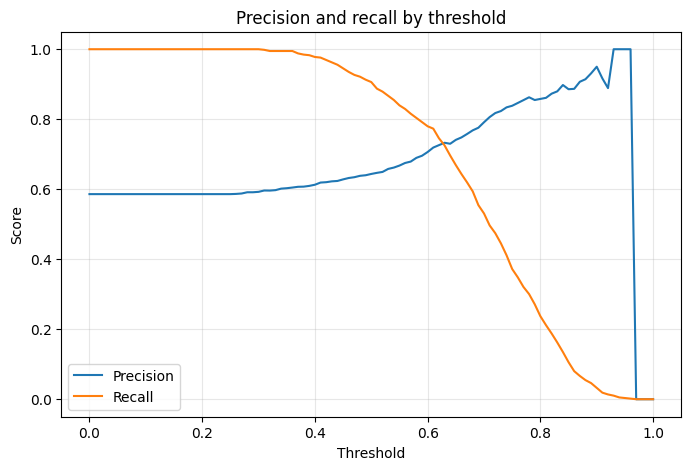

Q3 - Closest precision/recall intersection: threshold=0.63, precision=0.733, recall=0.725


In [3]:
from sklearn.metrics import precision_score, recall_score

thresholds = np.arange(0.0, 1.01, 0.01)
precisions = []
recalls = []
for threshold in thresholds:
    y_val_pred_label = (y_val_pred >= threshold).astype(int)
    precisions.append(precision_score(y_val, y_val_pred_label, zero_division=0))
    recalls.append(recall_score(y_val, y_val_pred_label, zero_division=0))

plt.figure(figsize=(8, 5))
plt.plot(thresholds, precisions, label="Precision")
plt.plot(thresholds, recalls, label="Recall")
plt.xlabel("Threshold")
plt.ylabel("Score")
plt.title("Precision and recall by threshold")
plt.grid(True, alpha=0.3)
plt.legend()
plt.show()

valid_intersections = [
    (abs(precision - recall), threshold, precision, recall)
    for threshold, precision, recall in zip(thresholds, precisions, recalls)
    if precision != 0 or recall != 0
]
_, intersection_threshold, intersection_precision, intersection_recall = min(
    valid_intersections, key=lambda item: item[0]
)
print(
    f"Q3 - Closest precision/recall intersection: threshold={intersection_threshold:.2f}, "
    f"precision={intersection_precision:.3f}, recall={intersection_recall:.3f}"
)

### Question 4: F1 score

In [4]:
f1_scores = []
for precision, recall in zip(precisions, recalls):
    denominator = precision + recall
    f1_scores.append(2 * precision * recall / denominator if denominator else 0.0)

best_f1_index = int(np.argmax(f1_scores))
print(
    f"Q4 - Maximum F1: {f1_scores[best_f1_index]:.3f} "
    f"at threshold {thresholds[best_f1_index]:.2f}"
)

Q4 - Maximum F1: 0.758 at threshold 0.41


### Question 5: 5-Fold CV

In [5]:
from sklearn.model_selection import KFold

kf = KFold(n_splits=5, shuffle=True, random_state=1)
fold_scores = []
for fold, (train_idx, val_idx) in enumerate(kf.split(df_full_train), start=1):
    fold_train = df_full_train.iloc[train_idx]
    fold_val = df_full_train.iloc[val_idx]

    fold_train_dicts = fold_train[features].to_dict(orient="records")
    fold_val_dicts = fold_val[features].to_dict(orient="records")
    fold_dv = DictVectorizer(sparse=False)
    X_fold_train = fold_dv.fit_transform(fold_train_dicts)
    X_fold_val = fold_dv.transform(fold_val_dicts)
    y_fold_train = fold_train[target].to_numpy()
    y_fold_val = fold_val[target].to_numpy()

    fold_model = LogisticRegression(solver="liblinear", C=1.0, max_iter=1000)
    fold_model.fit(X_fold_train, y_fold_train)
    fold_pred = fold_model.predict_proba(X_fold_val)[:, 1]
    fold_scores.append(roc_auc_score(y_fold_val, fold_pred))
    print(f"Fold {fold}: AUC={fold_scores[-1]:.3f}")

print(f"Q5 - Mean AUC: {np.mean(fold_scores):.3f}")
print(f"Q5 - Standard deviation: {np.std(fold_scores):.3f}")

Fold 1: AUC=0.731
Fold 2: AUC=0.730
Fold 3: AUC=0.736
Fold 4: AUC=0.741
Fold 5: AUC=0.721
Q5 - Mean AUC: 0.732
Q5 - Standard deviation: 0.007


### Question 6: Hyperparameter Tuning

In [6]:
c_values = [0.000001, 0.001, 1]
cv_results = {}
for c_value in c_values:
    scores = []
    for train_idx, val_idx in kf.split(df_full_train):
        fold_train = df_full_train.iloc[train_idx]
        fold_val = df_full_train.iloc[val_idx]

        fold_train_dicts = fold_train[features].to_dict(orient="records")
        fold_val_dicts = fold_val[features].to_dict(orient="records")
        fold_dv = DictVectorizer(sparse=False)
        X_fold_train = fold_dv.fit_transform(fold_train_dicts)
        X_fold_val = fold_dv.transform(fold_val_dicts)
        y_fold_train = fold_train[target].to_numpy()
        y_fold_val = fold_val[target].to_numpy()

        fold_model = LogisticRegression(
            solver="liblinear", C=c_value, max_iter=1000
        )
        fold_model.fit(X_fold_train, y_fold_train)
        fold_pred = fold_model.predict_proba(X_fold_val)[:, 1]
        scores.append(roc_auc_score(y_fold_val, fold_pred))

    cv_results[c_value] = (float(np.mean(scores)), float(np.std(scores)))
    mean_auc, std_auc = cv_results[c_value]
    print(f"C={c_value}: mean AUC={mean_auc:.3f}, std={std_auc:.3f}")

best_c = max(
    c_values,
    key=lambda c_value: (
        round(cv_results[c_value][0], 3),
        -round(cv_results[c_value][1], 3),
        -c_value,
    ),
)
print(f"Q6 - Best C: {best_c}")

C=1e-06: mean AUC=0.617, std=0.019
C=0.001: mean AUC=0.749, std=0.010
C=1: mean AUC=0.732, std=0.007
Q6 - Best C: 0.001
